# Simple inflation forecasting experiment
**Read raw data → clean monthly dates → compare three models → show results.**

This is a separate beginner experiment. Earlier notebooks and application results are unchanged.
We use only national headline inflation and monthly average PHP/USD. Policy rate and M3 are deliberately left for later experiments. This does not complete the proposal's full indicator-screening study.

Inflation is already a year-on-year percentage. Forecast errors are measured in **percentage points (pp)**. Run all cells using the project's `.venv` kernel. All preparation and model code is shown here; no `src` imports, database or web app are required.

In [1]:
from pathlib import Path
import calendar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

ROOT = Path.cwd() if (Path.cwd() / "data/raw").exists() else Path.cwd().parent
RAW = ROOT / "data/raw"
OUT = ROOT / "artifacts/simple_experiment"
OUT.mkdir(parents=True, exist_ok=True)
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.2})

## Inspect raw file structure
Before cleaning, view the original columns and a few rows. The CSV month columns must be turned into rows. The exchange-rate workbook has headings, blank rows and repeated year labels. We select only the required fields; no original file is overwritten.

In [2]:
raw_inflation = pd.read_csv(RAW / "Dataset-12019-2026.csv", sep=";", skiprows=2, na_values=[".."])
print("Raw inflation shape:", raw_inflation.shape)
display(raw_inflation.iloc[:, :8].head())
raw_exchange = pd.read_excel(RAW / "pesodollar.xlsx", sheet_name="monthly", header=None)
display(raw_exchange.iloc[:14, :5])

Raw inflation shape: (1, 98)


,Geolocation,Commodity Description,2019 Jan,2019 Feb,2019 Mar,2019 Apr,2019 May,2019 Jun
0,PHILIPPINES,0 - ALL ITEMS,4.4,3.8,3.4,3.2,3.2,2.7


,0,1,2,3,4
0,Philippine Peso per US Dollar Rate,NaN,NaN,NaN,NaN
1,for periods indicated,NaN,NaN,NaN,NaN
2,,NaN,,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
4,NaN,Period,NaN,Average,End-of-Period
5,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN
7,NaN,1945,January,2,n.a.
8,NaN,NaN,February,2,n.a.
9,NaN,NaN,March,2,n.a.


## 1. Read and clean inflation
The CSVs have a description above their table, use semicolons, and store months across columns.
Select the single **PHILIPPINES / 0 - ALL ITEMS** row, turn month labels into dates, and join the two periods. `..` means missing, not zero. Use January 2010–July 2026 to match the original primary period.

In [3]:
inflation_parts = []
for filename in ["Dataset-11995-2018.csv", "Dataset-12019-2026.csv"]:
    table = pd.read_csv(RAW / filename, sep=";", skiprows=2, na_values=[".."]) 
    selected = table[(table["Geolocation"] == "PHILIPPINES") &
                     (table["Commodity Description"] == "0 - ALL ITEMS")]
    assert len(selected) == 1, "Expected one national all-items row"
    values = selected.iloc[0, 2:]
    values.index = pd.to_datetime(values.index, format="%Y %b")
    inflation_parts.append(pd.to_numeric(values, errors="raise"))

inflation = pd.concat(inflation_parts).sort_index()
assert inflation.index.is_unique, "Duplicate inflation months"
inflation = inflation.loc["2010-01-01":"2026-07-01"].rename("inflation")
display(inflation.to_frame().head())

,inflation
2010-01-01,3.9
2010-02-01,3.9
2010-03-01,3.9
2010-04-01,4.0
2010-05-01,3.9


## 2. Read monthly average PHP/USD
The workbook repeats a year only at the beginning of that year. Forward-fill **year labels**, not missing exchange-rate values. Use the `Average` column on the `monthly` sheet. Ignore annual, daily and end-of-period values.

In [4]:
sheet = pd.read_excel(RAW / "pesodollar.xlsx", sheet_name="monthly", header=None)
exchange = sheet.iloc[:, [1, 2, 3]].copy()
exchange.columns = ["year", "month", "exchange_rate"]
exchange["year"] = pd.to_numeric(exchange["year"], errors="coerce").ffill()
month_numbers = {name: number for number, name in enumerate(calendar.month_name) if name}
exchange["month"] = exchange["month"].astype(str).str.strip().map(month_numbers)
exchange["exchange_rate"] = pd.to_numeric(exchange["exchange_rate"], errors="coerce")
exchange = exchange.dropna(subset=["year", "month", "exchange_rate"])
exchange["date"] = pd.to_datetime(dict(year=exchange["year"].astype(int),
                                     month=exchange["month"].astype(int), day=1))
exchange = exchange.set_index("date")["exchange_rate"].sort_index()
assert exchange.index.is_unique, "Duplicate exchange-rate months"

data = pd.concat([inflation, exchange], axis=1).loc["2010-01-01":"2026-07-01"]
data = data.asfreq("MS")
data.index.name = "date"
assert len(data) == 199 and data.index.is_unique
assert data.notna().all().all(), "Review missing months instead of inventing values"
display(data.head(), data.tail())
display(data.isna().sum().rename("missing values").to_frame())
data.to_csv(OUT / "monthly_data.csv")

C:\Users\Luzan\AppData\Local\Temp\ipykernel_13684\3031318081.py:14: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  data = pd.concat([inflation, exchange], axis=1).loc["2010-01-01":"2026-07-01"]


,inflation,exchange_rate
date,,
2010-01-01,3.9,46.027600
2010-02-01,3.9,46.311600
2010-03-01,3.9,45.742478
2010-04-01,4.0,44.626579
2010-05-01,3.9,45.597105


,inflation,exchange_rate
date,,
2026-03-01,4.1,59.406905
2026-04-01,7.2,60.291316
2026-05-01,6.8,61.441000
2026-06-01,6.4,61.251286
2026-07-01,6.2,61.596261


,missing values
inflation,0
exchange_rate,0


## Cleaning check before modeling
The cleaning steps above remove non-data spreadsheet rows, strip month-label spaces, turn dates/numbers into usable types, and join matching months. Here we check the result. Missing source observations and conflicting duplicate months should be reviewed, not hidden by filling or keeping an arbitrary row. We do not remove inflation spikes merely because they are large: they can be real observations.

In [5]:
cleaning_check = pd.DataFrame({
    "check": ["Monthly records", "Duplicate dates", "Missing inflation", "Missing exchange rate",
              "Nonpositive exchange rates", "Expected months"],
    "result": [len(data), int(data.index.duplicated().sum()), int(data["inflation"].isna().sum()),
               int(data["exchange_rate"].isna().sum()), int(data["exchange_rate"].le(0).sum()), 199]
})
display(cleaning_check)
display(data.dtypes.rename("data type").to_frame())
assert data.index.equals(pd.date_range("2010-01-01", "2026-07-01", freq="MS", name="date"))
assert data["exchange_rate"].gt(0).all()
print("Cleaning complete: 199 unique, continuous months with both required variables.")
print("No inflation interpolation, outlier deletion or artificial exchange-rate filling was used.")

,check,result
0,Monthly records,199
1,Duplicate dates,0
2,Missing inflation,0
3,Missing exchange rate,0
4,Nonpositive exchange rates,0
5,Expected months,199


,data type
inflation,float64
exchange_rate,float64


Cleaning complete: 199 unique, continuous months with both required variables.
No inflation interpolation, outlier deletion or artificial exchange-rate filling was used.


## 3. View the prepared data
Show each variable in its own unit. These historical lines do not establish causality.

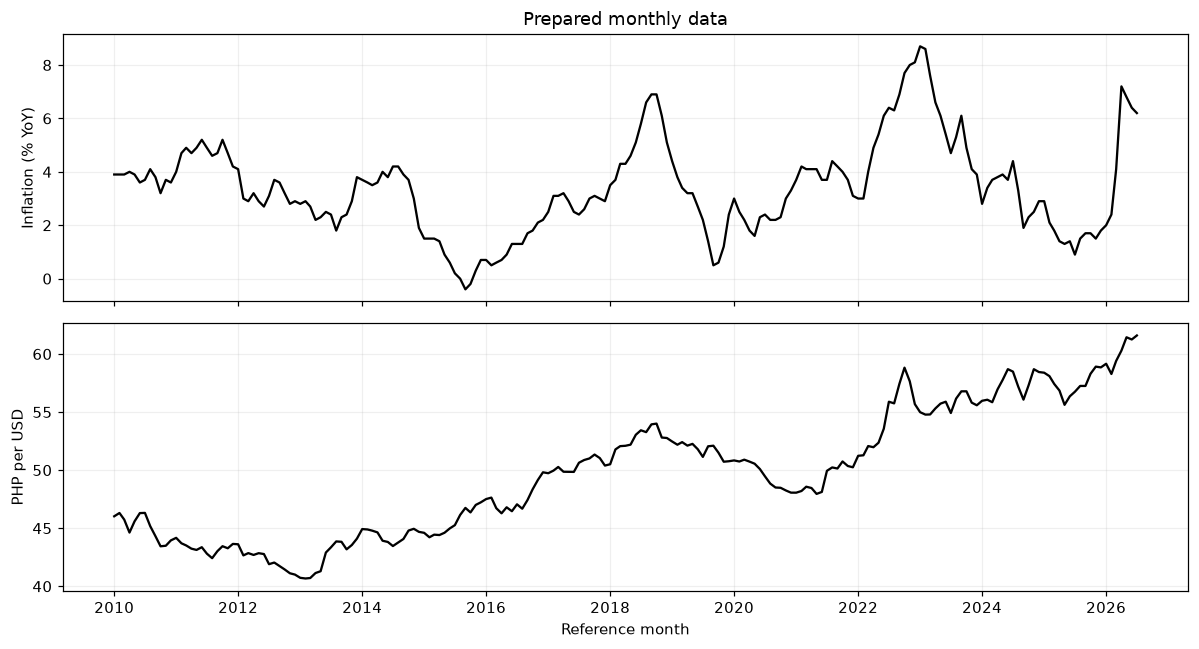

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(data.index, data["inflation"], color="black")
axes[0].set_ylabel("Inflation (% YoY)")
axes[0].set_title("Prepared monthly data")
axes[1].plot(data.index, data["exchange_rate"], color="black")
axes[1].set_ylabel("PHP per USD")
axes[1].set_xlabel("Reference month")
fig.tight_layout()
fig.savefig(OUT / "01_prepared_data.png")
plt.show()
plt.close(fig)

## 4. Make one lagged predictor and chronological blocks
For a target month, use the exchange rate from **five months earlier**. At horizon three, this is two months before the forecast origin, so actual future exchange rates are not required.

This is a fixed illustrative delay assumption, not a searched best lag. Original release dates and historical vintages were not supplied; the experiment is retrospective. The first five rows cannot have this lag and are removed. No scaling, interpolation or additional feature engineering is necessary here.

Use the twelve months before the final twelve as validation. Choose among the three fixed models on validation only, then report the final block. These months were seen in earlier work, so this is **not a new untouched test**. Do not repeatedly tune to these results.

In [7]:
data["exchange_lag5"] = data["exchange_rate"].shift(5)
model_data = data.dropna(subset=["inflation", "exchange_lag5"]).copy()
validation_months = model_data.index[-24:-12]
test_months = model_data.index[-12:]

split_table = pd.DataFrame({
    "target block": ["Validation", "Previously seen test"],
    "from": [validation_months[0], test_months[0]],
    "through": [validation_months[-1], test_months[-1]],
    "target months per horizon": [len(validation_months), len(test_months)]
})
display(split_table)
print("Source months:", len(data), "| Common model months:", len(model_data))
print("The training window ends at each forecast origin, before its target.")

,target block,from,through,target months per horizon
0,Validation,2024-08-01,2025-07-01,12
1,Previously seen test,2025-08-01,2026-07-01,12


Source months: 199 | Common model months: 194
The training window ends at each forecast origin, before its target.


## 5. Define the three models
1. **Naive:** repeat the last known inflation rate.
2. **SARIMA:** use historical inflation with order `(1,0,0)` and seasonal order `(1,0,0,12)`.
3. **SARIMAX:** use the same orders plus the five-month-lagged exchange rate.

The orders are fixed introductory choices inherited from the earlier baseline; this notebook does not claim they are optimal. `1,0,0` means one autoregressive term, no differencing and no moving-average term. Seasonal `12` means twelve months. The statistical models include an intercept. Defaults enforce stationarity/invertibility. We check numerical convergence rather than suppress warnings or substitute a different model when fitting fails.

In [8]:
models = ["Naive", "SARIMA", "SARIMAX"]

def make_forecast(name, train, future_x):
    steps = len(future_x)
    if name == "Naive":
        return np.repeat(train["inflation"].iloc[-1], steps), None

    train_x = train[["exchange_lag5"]] if name == "SARIMAX" else None
    forecast_x = future_x if name == "SARIMAX" else None
    fitted = SARIMAX(train["inflation"], exog=train_x, order=(1, 0, 0),
                     seasonal_order=(1, 0, 0, 12), trend="c").fit(disp=False, maxiter=200)
    assert fitted.mle_retvals["converged"], f"{name} fit did not converge"
    forecast = fitted.get_forecast(steps=steps, exog=forecast_x)
    return np.asarray(forecast.predicted_mean), fitted

## 6. Generate earlier-origin predictions
For every target, go back one, two or three months to its origin. Fit only on observations through that origin, then predict the requested horizon. All models use the same target dates and training sample.

The short loop below does more fits than a cached implementation, but its steps are easier to follow. The assertion verifies that even the last required exchange observation is old enough. Using earlier test observations at later origins is an expanding-window evaluation, not fitting a target to itself.

In [9]:
records = []
for phase, target_months in [("Validation", validation_months), ("Test", test_months)]:
    for target in target_months:
        for horizon in [1, 2, 3]:
            origin = target - pd.DateOffset(months=horizon)
            train = model_data.loc[:origin]
            future_dates = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
            future_x = model_data.loc[future_dates, ["exchange_lag5"]]
            assert target - pd.DateOffset(months=5) <= origin - pd.DateOffset(months=2)
            for name in models:
                predicted, fitted = make_forecast(name, train, future_x)
                actual = model_data.loc[target, "inflation"]
                records.append({"phase": phase, "model": name, "origin": origin,
                                "target": target, "horizon": horizon, "actual": actual,
                                "predicted": predicted[-1], "error": predicted[-1] - actual})
    print(phase, "complete")

results = pd.DataFrame(records)
assert len(results) == 2 * 12 * 3 * 3
assert results.groupby(["phase", "model", "horizon"]).size().eq(12).all()
assert np.isfinite(results[["actual", "predicted", "error"]]).all().all()
display(results.head(9).round(4))

Validation complete


Test complete


C:\Users\Luzan\AppData\Local\Temp\ipykernel_13684\2315425709.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(results.head(9).round(4))


,phase,model,origin,target,horizon,actual,predicted,error
0,Validation,Naive,2024-07-01,2024-08-01,1,3.3,4.4000,1.1000
1,Validation,SARIMA,2024-07-01,2024-08-01,1,3.3,4.0877,0.7877
2,Validation,SARIMAX,2024-07-01,2024-08-01,1,3.3,4.0876,0.7876
3,Validation,Naive,2024-06-01,2024-08-01,2,3.3,3.7000,0.4000
4,Validation,SARIMA,2024-06-01,2024-08-01,2,3.3,3.7088,0.4088
5,Validation,SARIMAX,2024-06-01,2024-08-01,2,3.3,3.7092,0.4092
6,Validation,Naive,2024-05-01,2024-08-01,3,3.3,3.9000,0.6000
7,Validation,SARIMA,2024-05-01,2024-08-01,3,3.3,4.2020,0.9020
8,Validation,SARIMAX,2024-05-01,2024-08-01,3,3.3,4.2025,0.9025


## 7. Compare actual results
**MAE** = mean absolute error. **RMSE** = square root of mean squared error. Both use percentage points; smaller is better. Average the three validation-horizon RMSEs to select one model. Test results do not change that choice.

In [10]:
results["absolute_error"] = results["error"].abs()
results["squared_error"] = results["error"] ** 2
metrics = results.groupby(["phase", "model", "horizon"]).agg(
    MAE=("absolute_error", "mean"), MSE=("squared_error", "mean"), N=("error", "size")
).reset_index()
metrics["RMSE"] = np.sqrt(metrics["MSE"])
metrics = metrics[["phase", "model", "horizon", "MAE", "RMSE", "N"]]
validation_scores = metrics[metrics["phase"] == "Validation"].groupby("model")["RMSE"].mean().sort_values()
selected_model = validation_scores.index[0]
display(validation_scores.rename("mean validation RMSE").to_frame().round(4))
display(metrics.round(4))
print("Selected using validation only:", selected_model)
results.to_csv(OUT / "predictions.csv", index=False)
metrics.to_csv(OUT / "metrics.csv", index=False)

,mean validation RMSE
model,
SARIMAX,0.7557
SARIMA,0.7573
Naive,0.8968


,phase,model,horizon,MAE,RMSE,N
0,Test,Naive,1,0.6417,1.0642,12
1,Test,Naive,2,1.1250,1.7581,12
2,Test,Naive,3,1.4833,2.2297,12
3,Test,SARIMA,1,0.5830,0.9878,12
4,Test,SARIMA,2,0.9900,1.5680,12
5,Test,SARIMA,3,1.3699,1.9272,12
6,Test,SARIMAX,1,0.5828,0.9901,12
7,Test,SARIMAX,2,1.0092,1.5902,12
8,Test,SARIMAX,3,1.3914,1.9569,12
9,Validation,Naive,1,0.4750,0.6252,12


Selected using validation only: SARIMAX


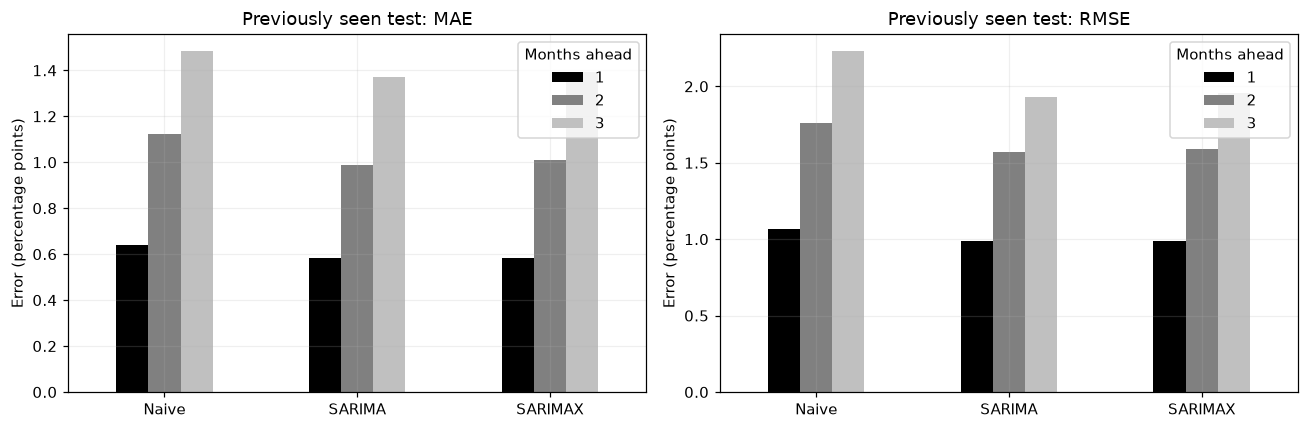

SARIMAX, 1 month(s): MAE 0.583 pp, RMSE 0.990 pp (12 targets).
SARIMAX, 2 month(s): MAE 1.009 pp, RMSE 1.590 pp (12 targets).
SARIMAX, 3 month(s): MAE 1.391 pp, RMSE 1.957 pp (12 targets).
These are historical error sizes, not percentage accuracy scores.


In [11]:
test_metrics = metrics[metrics["phase"] == "Test"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, measure in zip(axes, ["MAE", "RMSE"]):
    table = test_metrics.pivot(index="model", columns="horizon", values=measure).reindex(models)
    table.plot.bar(ax=axis, color=["black", "gray", "silver"], rot=0)
    axis.set_title("Previously seen test: " + measure)
    axis.set_ylabel("Error (percentage points)")
    axis.set_xlabel("")
    axis.legend(title="Months ahead")
fig.tight_layout()
fig.savefig(OUT / "02_model_comparison.png")
plt.show()
plt.close(fig)

selected_metrics = test_metrics[test_metrics["model"] == selected_model]
for row in selected_metrics.itertuples():
    print(f"{selected_model}, {row.horizon} month(s): MAE {row.MAE:.3f} pp, RMSE {row.RMSE:.3f} pp ({row.N} targets).")
print("These are historical error sizes, not percentage accuracy scores.")

## 8. Plot actual versus predicted inflation
Each panel uses the selected model and a different horizon. Large gaps mean larger forecasting errors, particularly around sudden inflation changes.

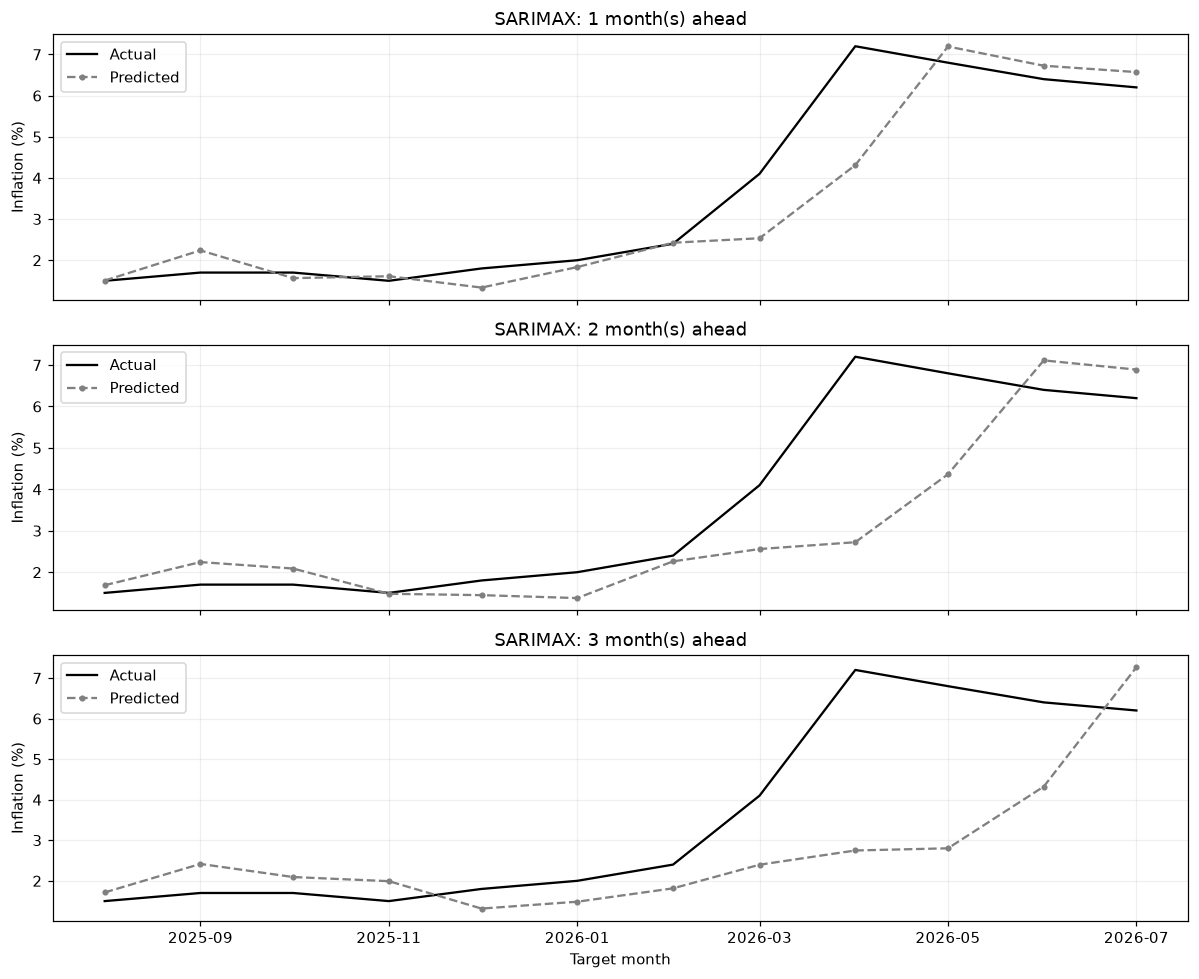

In [12]:
selected_results = results[(results["phase"] == "Test") & (results["model"] == selected_model)]
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for axis, horizon in zip(axes, [1, 2, 3]):
    rows = selected_results[selected_results["horizon"] == horizon].sort_values("target")
    axis.plot(rows["target"], rows["actual"], label="Actual", color="black")
    axis.plot(rows["target"], rows["predicted"], label="Predicted", color="gray", linestyle="--", marker="o", markersize=3)
    axis.set_title(f"{selected_model}: {horizon} month(s) ahead")
    axis.set_ylabel("Inflation (%)")
    axis.legend()
axes[-1].set_xlabel("Target month")
fig.tight_layout()
fig.savefig(OUT / "03_actual_vs_predicted.png")
plt.show()
plt.close(fig)

## 9. Refit and forecast three months
Use the fixed July 2026 origin, then construct the three future predictor rows explicitly from earlier exchange-rate observations. Show a basic residual check for the fitted statistical winner. Convergence alone is not model adequacy. A Ljung–Box p-value below 0.05 suggests residual autocorrelation remains; it does not determine which model to select after testing.

In [13]:
origin = model_data.index[-1]
future_dates = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=3, freq="MS")
source_dates = future_dates - pd.DateOffset(months=5)
assert (source_dates <= origin - pd.DateOffset(months=2)).all()
future_x = pd.DataFrame({"exchange_lag5": data.loc[source_dates, "exchange_rate"].to_numpy()}, index=future_dates)
forecast_values, final_fit = make_forecast(selected_model, model_data, future_x)
forecast_table = pd.DataFrame({"target": future_dates, "forecast": forecast_values})
if final_fit is not None:
    bounds = np.asarray(final_fit.get_forecast(steps=3, exog=future_x if selected_model == "SARIMAX" else None).conf_int())
    forecast_table["lower_95"] = bounds[:, 0]
    forecast_table["upper_95"] = bounds[:, 1]
    residuals = final_fit.resid.iloc[24:]
    residual_check = acorr_ljungbox(residuals, lags=[12], model_df=2, return_df=True)
    display(residual_check.round(5))
    if residual_check["lb_pvalue"].iloc[0] < 0.05:
        print("Review needed: residual autocorrelation remains. Forecasts are provisional.")
    else:
        print("No rejection at this residual-check lag; this is not proof of full adequacy.")
else:
    print("Naive benchmark selected: no fitted SARIMA residual diagnostics or interval calculation.")
display(forecast_table.round(4))
forecast_table.to_csv(OUT / "forecast.csv", index=False)

,lb_stat,lb_pvalue
12,37.4095,0.00005


Review needed: residual autocorrelation remains. Forecasts are provisional.


C:\Users\Luzan\AppData\Local\Temp\ipykernel_13684\2351218064.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast_table.round(4))


,target,forecast,lower_95,upper_95
0,2026-08-01,5.9215,5.0036,6.8395
1,2026-09-01,5.8343,4.5562,7.1124
2,2026-10-01,5.8447,4.3034,7.3861


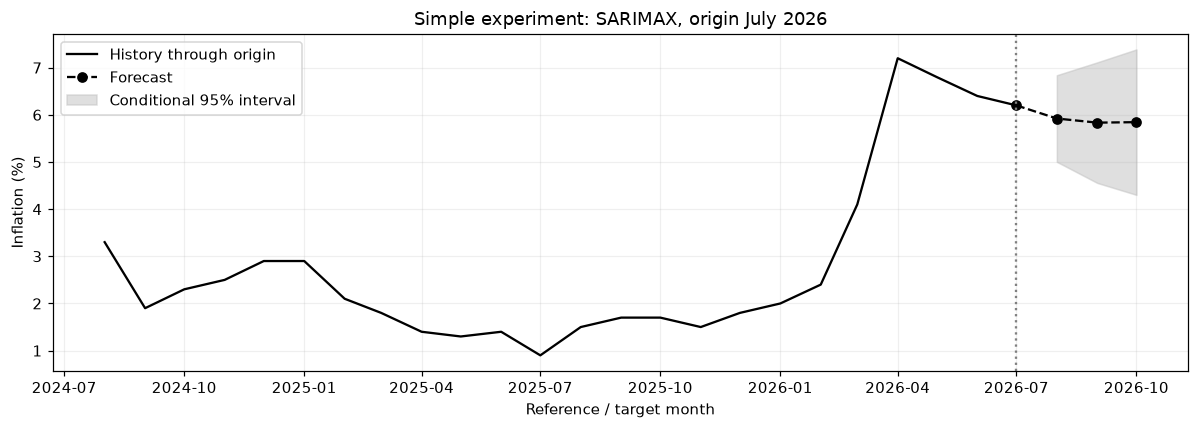

**Conclusion:** SARIMAX had the lowest mean validation RMSE among these three fixed candidates. Read the test table for its actual error sizes at each horizon. This limited retrospective experiment does not prove a causal effect of exchange rates, establish an optimal model, or replace an official forecast. The previously inspected test months and unknown historical release dates limit the strength of the evaluation.

In [14]:
fig, axis = plt.subplots(figsize=(11, 4))
history = data["inflation"].iloc[-24:]
axis.plot(history.index, history, color="black", label="History through origin")
axis.plot([origin, *future_dates], [history.iloc[-1], *forecast_values],
          color="black", linestyle="--", marker="o", label="Forecast")
if "lower_95" in forecast_table:
    axis.fill_between(future_dates, forecast_table["lower_95"], forecast_table["upper_95"],
                      color="silver", alpha=0.5, label="Conditional 95% interval")
axis.axvline(origin, color="gray", linestyle=":")
axis.set_title(f"Simple experiment: {selected_model}, origin July 2026")
axis.set_ylabel("Inflation (%)")
axis.set_xlabel("Reference / target month")
axis.legend()
fig.tight_layout()
fig.savefig(OUT / "04_three_month_forecast.png")
plt.show()
plt.close(fig)

display(Markdown(f"**Conclusion:** {selected_model} had the lowest mean validation RMSE among these three fixed candidates. "
    "Read the test table for its actual error sizes at each horizon. This limited retrospective experiment "
    "does not prove a causal effect of exchange rates, establish an optimal model, or replace an official forecast. "
    "The previously inspected test months and unknown historical release dates limit the strength of the evaluation."))

## Result to discuss
SARIMAX wins the validation ranking by a very small margin. On the previously seen test block, however, SARIMA has slightly lower RMSE at all three horizons: **0.988, 1.568, 1.927 pp**, compared with SARIMAX **0.990, 1.590, 1.957 pp**. Therefore this experiment does not show a clear benefit from adding the exchange rate. We keep the validation-selected model for the forecast rather than switching after seeing test results. Both statistical models lag the sudden 2026 rise, particularly at longer horizons. Check the residual result above before treating the forecast as adequate.